# **4. Exploratory Component: The Cost of Hoarding**

**Research question:** How much revenue and charging capacity is the company losing due to hoarding, and can we predict at plug-in which sessions will hoard, so that a targeted idle fee can discourage it?

## 4.1. Preparing the data

Libraries for data handling and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

Cleaned sessions from the pre-processing notebook (Section 1.5).

In [2]:
ev = pd.read_pickle("Data/ev_clean.pkl")
print(ev.shape)
# just to see the first few rows of the data
ev[["station", "start", "end", "total_hours", "charging_hours", "idle_hours", "energy_kwh", "fee", "user_id"]].head()

(245736, 27)


,station,start,end,total_hours,charging_hours,idle_hours,energy_kwh,fee,user_id
0,PALO ALTO CA / HAMILTON #1,2011-07-29 20:17:00,2011-07-29 23:20:32,3.058889,1.900833,1.158056,6.249457,0.0,3284
1,PALO ALTO CA / HAMILTON #1,2011-07-30 00:00:00,2011-07-30 00:02:06,0.035000,0.031667,0.003333,0.106588,0.0,4169
2,PALO ALTO CA / HAMILTON #1,2011-07-30 08:16:00,2011-07-30 12:33:32,4.292222,4.291111,0.001111,14.951777,0.0,4169
3,PALO ALTO CA / HAMILTON #1,2011-07-30 14:51:00,2011-07-30 16:54:24,2.056667,2.049444,0.007222,7.159643,0.0,2545
4,PALO ALTO CA / HAMILTON #1,2011-07-30 18:51:00,2011-07-30 20:02:24,1.190000,0.731667,0.458333,1.957765,0.0,3765


A session counts as hoarding when the car stays plugged in for more than one hour after charging has finished. A two-hour version is kept to check later that the conclusions do not depend on this threshold.

In [3]:
HOARD_THRESHOLD = 1  # hours of idle time

ev["hoarding"] = (ev["idle_hours"] > HOARD_THRESHOLD).astype(int) # > 1 hour of idle = hoarding
ev["hoarding_2h"] = (ev["idle_hours"] > 2).astype(int) # 2 hours of idle

print(f"Hoarding sessions (> 1 h idle): {ev['hoarding'].sum():,} ({ev['hoarding'].mean() * 100:.1f}%)")
print(f"Hoarding sessions (> 2 h idle): {ev['hoarding_2h'].sum():,} ({ev['hoarding_2h'].mean() * 100:.1f}%)")

Hoarding sessions (> 1 h idle): 30,409 (12.4%)
Hoarding sessions (> 2 h idle): 14,868 (6.1%)


Checks: idle time should never be negative after cleaning, and the target must have no missing values.

In [4]:
#just to check again 
print("Negative idle time:", (ev["idle_hours"] < 0).sum())
print("Missing idle time:", ev["idle_hours"].isna().sum())
print("Missing target:", ev["hoarding"].isna().sum())
ev["idle_hours"].describe().round(2)

Negative idle time: 0
Missing idle time: 0
Missing target: 0


count    245736.00
mean          0.50
std           1.40
min           0.00
25%           0.00
50%           0.01
75%           0.37
max          22.40
Name: idle_hours, dtype: float64

## 4.2. Describing the problem

Share of hoarding sessions by the hour the car is plugged in.

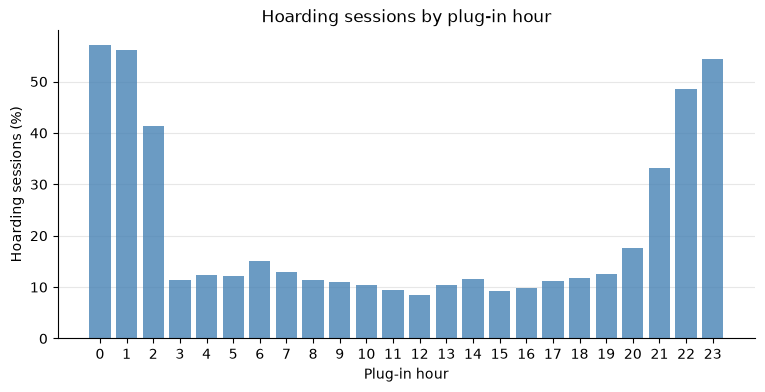

In [5]:
# start hour of the session
ev["start_hour"] = ev["start"].dt.hour  

# percentage of hoarding sessions by hour
by_hour = ev.groupby("start_hour")["hoarding"].mean() * 100 

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values, color="steelblue", alpha=0.8)
ax.set_title("Hoarding sessions by plug-in hour")
ax.set_xlabel("Plug-in hour")
ax.set_ylabel("Hoarding sessions (%)")
ax.set_xticks(range(0, 24))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Share of hoarding sessions by station.

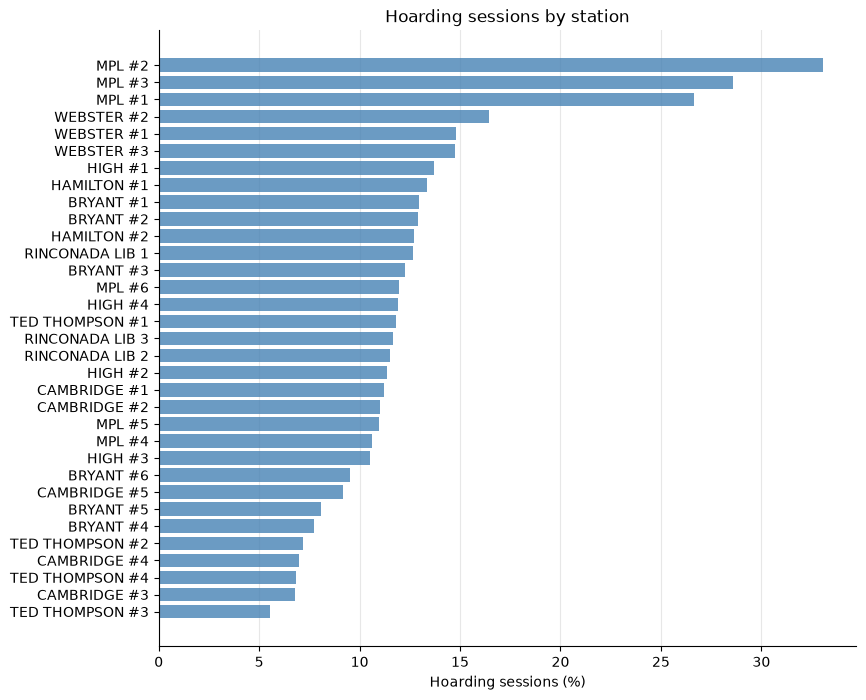

In [6]:
# percentage of hoarding sessions by station
by_station = (ev.groupby("station", observed=True)["hoarding"].mean() * 100).sort_values() 

# remove PALO ALTO  from the name
by_station.index = by_station.index.str.replace("PALO ALTO CA / ", "") 

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(by_station.index, by_station.values, color="steelblue", alpha=0.8)
ax.set_title("Hoarding sessions by station")
ax.set_xlabel("Hoarding sessions (%)")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

Charger hours blocked by hoarding each year. Idle time is counted as daytime when charging finishes between 07:00 and 22:00, when other drivers are more likely to need the charger.

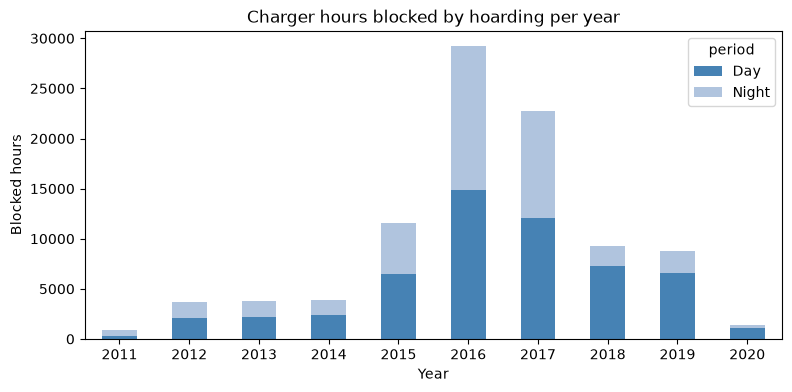

period      Day    Night
start                   
2011      324.0    557.0
2012     2130.0   1574.0
2013     2178.0   1572.0
2014     2379.0   1531.0
2015     6493.0   5094.0
2016    14860.0  14411.0
2017    12053.0  10710.0
2018     7302.0   1963.0
2019     6606.0   2214.0
2020     1079.0    358.0


In [7]:
# hour when the idle period starts
ev["idle_start_hour"] = (ev["start"] + pd.to_timedelta(ev["charging_hours"], unit="h")).dt.hour 

# daytime = 7-21, nighttime = 22-6
ev["period"] = np.where(ev["idle_start_hour"].between(7, 21), "Day", "Night") 

# blocked hours by hoarding per year
blocked = (ev[ev["hoarding"] == 1]
           .groupby([ev["start"].dt.year, "period"])["idle_hours"].sum()
           .unstack())

blocked.plot(kind="bar", stacked=True, figsize=(9, 4), color=["steelblue", "lightsteelblue"])
plt.title("Charger hours blocked by hoarding per year")
plt.xlabel("Year")
plt.ylabel("Blocked hours")
plt.xticks(rotation=0)
plt.show()

print(blocked.round(0))

Daytime charger hours blocked by hoarding per year at each station (top 10). Only 2018 and 2019 are used: every session was paid and all 33 stations were open (six of them from March 2018), so older stations do not get a higher total just for having more years of data.

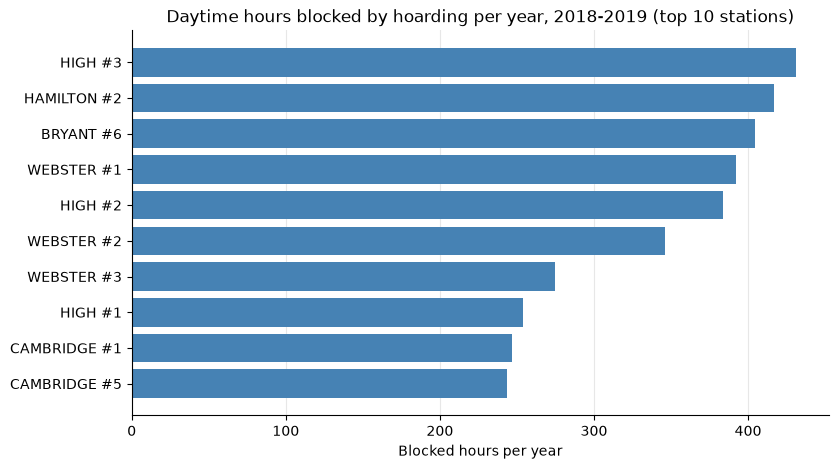

station
HIGH #3         431.0
HAMILTON #2     417.0
BRYANT #6       404.0
WEBSTER #1      392.0
HIGH #2         384.0
WEBSTER #2      346.0
WEBSTER #3      275.0
HIGH #1         254.0
CAMBRIDGE #1    247.0
CAMBRIDGE #5    244.0
Name: idle_hours, dtype: float64


In [ ]:
# using only 2018 and 2019, because 2020 is not a full year and 2021 has very few sessions
recent = ev[ev["start"].dt.year.isin([2018, 2019])] 

day_blocked = (recent[(recent["hoarding"] == 1) & (recent["period"] == "Day")]
               .groupby("station", observed=True)["idle_hours"].sum() / 2  # two years, so hours per year
               ).sort_values().tail(10)
day_blocked.index = day_blocked.index.str.replace("PALO ALTO CA / ", "")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(day_blocked.index, day_blocked.values, color="steelblue")
ax.set_title("Daytime hours blocked by hoarding per year, 2018-2019 (top 10 stations)")
ax.set_xlabel("Blocked hours per year")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(day_blocked.round(0).sort_values(ascending=False))

**Key findings.** Most hoarding happens at night: about half of the sessions that start between 22:00 and 01:00 hoard, compared with about 10% of daytime sessions. Blocked hours peaked in 2016. From 2018, when every session was paid, night hoarding dropped sharply, but daytime hoarding stayed at about 7,000 hours a year.

MPL #1 to #3 have the highest hoarding rates (27 to 33%), but they are among the least used chargers, so their hoarding blocks few drivers. For that reason we compare stations by the daytime hours they lose to hoarding each year, using only 2018 and 2019. In those two years every session was paid and all stations were open, so stations that opened earlier do not score higher just because they have more years of data. On that measure the worst stations are HIGH #3, HAMILTON #2, BRYANT #6 and WEBSTER #1, each with about 400 blocked hours a year.